# MLT Homework 3: Optimization algorithms
**Hazem Daw | Group J4132**

This notebook compares gradient descent (GD), stochastic gradient descent (SGD)
and Adam for logistic regression on the biological response dataset. The aim is
to examine how the optimizer and learning rate affect loss and classification accuracy.
The implementation uses NumPy. The plots are drawn as SVG using Python strings.

## 1. Data preparation
`bioresponse.csv` contains 3,751 molecules and 1,776 molecular descriptors.
The target, `Activity`, is 1 if the molecule produces the biological response and 0 otherwise.

The data is split into 2,813 training rows (75%) and 938 test rows (25%), using a
stratified split with seed 42. Within the training set, 2,250 rows are used for
fitting and 563 for validation during learning-rate selection. The selected models
are then trained again on all 2,813 training rows before testing.

The descriptors are already in [0, 1]. Each feature is centered by subtracting
its training mean. During selection, the means come from the 2,250 fitting rows;
for the final models, they come from the full training set. Centering improves
conditioning and preserves the model class because the intercept is fitted too.
All rows and descriptors are retained. No regularization or early stopping is used.

In [1]:
import numpy as np

SEED = 42
EPOCHS = 200
LEARNING_RATES = (0.0001, 0.001, 0.01, 0.1, 1.0)
METHODS = ("GD", "SGD", "Adam")

data = np.loadtxt("bioresponse.csv", delimiter=",", skiprows=1, dtype=np.float64)
with open("bioresponse.csv", encoding="utf-8") as file:
    columns = file.readline().strip().split(",")
X_raw, y = data[:, 1:], data[:, 0].astype(np.int64)
assert columns[0] == "Activity" and X_raw.shape == (3751, 1776)
assert np.isfinite(data).all() and np.array_equal(np.unique(data[:, 0]), [0, 1])
assert X_raw.min() >= 0 and X_raw.max() <= 1
print(f"NumPy {np.__version__}; data: {len(y):,} molecules, {X_raw.shape[1]:,} descriptors")
print("Class counts (0, 1):", np.bincount(y))
print("Missing/nonfinite values:", np.count_nonzero(~np.isfinite(data)))
print("Constant descriptors:", np.count_nonzero(np.ptp(X_raw, axis=0) == 0))


def stratified_split(labels, train_fraction, seed):
    """Return disjoint indices, with exactly floor(fraction * n) training rows."""
    rng = np.random.default_rng(seed)
    classes, counts = np.unique(labels, return_counts=True)
    quotas = train_fraction * counts
    n_train = np.floor(quotas).astype(int)
    remainder = int(np.floor(train_fraction * labels.size)) - int(n_train.sum())
    n_train[np.argsort(-(quotas - n_train), kind="stable")[:remainder]] += 1
    train, test = [], []
    for label, count in zip(classes, n_train):
        indices = rng.permutation(np.flatnonzero(labels == label))
        train.extend(indices[:count])
        test.extend(indices[count:])
    return rng.permutation(train), rng.permutation(test)


train_idx, test_idx = stratified_split(y, 0.75, SEED)
inner_fit, inner_val = stratified_split(y[train_idx], 0.8, SEED + 1)
fit_idx, val_idx = train_idx[inner_fit], train_idx[inner_val]
assert train_idx.size == 2813 and test_idx.size == 938
assert np.intersect1d(train_idx, test_idx).size == 0
assert np.intersect1d(fit_idx, val_idx).size == 0
assert np.array_equal(np.sort(np.concatenate((train_idx, test_idx))), np.arange(len(y)))

# Keep the reference notebook's convention: X is (features, samples), Y is (1, samples).
inner_mean = X_raw[fit_idx].mean(axis=0)
X_fit = np.asfortranarray((X_raw[fit_idx] - inner_mean).T)
X_val = np.asfortranarray((X_raw[val_idx] - inner_mean).T)
Y_fit, Y_val = y[fit_idx][None, :], y[val_idx][None, :]
for label, indices in (("Full training", train_idx), ("Inner fitting", fit_idx),
                       ("Validation", val_idx), ("Held-out test", test_idx)):
    print(f"{label:15s}: {indices.size:4d} rows; class counts {np.bincount(y[indices])}")

NumPy 2.3.5; data: 3,751 molecules, 1,776 descriptors
Class counts (0, 1): [1717 2034]
Missing/nonfinite values: 0
Constant descriptors: 0
Full training  : 2813 rows; class counts [1288 1525]
Inner fitting  : 2250 rows; class counts [1030 1220]
Validation     :  563 rows; class counts [258 305]
Held-out test  :  938 rows; class counts [429 509]


## Logistic regression and backpropagation
The implementation follows the functions in the course notebook:
`sigmoid`, `initialize_with_zeros`, `propagate`, `optimize`, `predict` and `model`.

For $X\in\mathbb{R}^{d\times m}$, $w\in\mathbb{R}^{d\times 1}$ and scalar $b$:
$$Z=w^T X+b,\qquad A=\sigma(Z),\qquad
J=\frac1m\sum_i\left[\log(1+e^{z_i})-y_i z_i\right].$$
The gradients of the binary cross-entropy loss are
$$\nabla_w J=\frac1m X(A-Y)^T,\qquad
\nabla_b J=\frac1m\sum_i(a_i-y_i).$$

For binary labels, `logaddexp(0, (1 - 2Y) * Z)` is equivalent to the expression
above and avoids numerical problems at large logits. The sigmoid is also computed
without exponentiating large positive values.

Weights and bias start at zero. The prediction threshold is 0.5, with ties assigned
to class 0. These choices are the same for every experiment.

In [2]:
def sigmoid(z):
    z = np.asarray(z, dtype=np.float64)
    e = np.exp(-np.abs(z))
    return np.where(z >= 0, 1.0 / (1.0 + e), e / (1.0 + e))


def initialize_with_zeros(dim):
    return np.zeros((dim, 1), dtype=np.float64), 0.0


def binary_loss(logits, Y):
    return float(np.mean(np.logaddexp(0.0, (1.0 - 2.0 * Y) * logits)))


def propagate(w, b, X, Y):
    logits = w.T @ X + b
    error = sigmoid(logits) - Y
    grads = {"dw": X @ error.T / X.shape[1], "db": float(error.mean())}
    return grads, binary_loss(logits, Y)


def predict(w, b, X, threshold=0.5):
    return (sigmoid(w.T @ X + b) > threshold).astype(np.int64)


def evaluate(w, b, X, Y):
    logits = w.T @ X + b
    return {"loss": binary_loss(logits, Y),
            "accuracy": float(np.mean((logits > 0) == Y))}

## 2-3. Optimization methods
**GD** uses the full training set for each gradient:
$\theta\leftarrow\theta-\alpha g$.

**SGD** updates the parameters after each individual molecule. The rows are shuffled
without replacement at the beginning of each epoch. For one example,
$g_w=x_i(a_i-y_i)$ and $g_b=a_i-y_i$.

**Adam** uses shuffled mini-batches of 64 molecules. The last batch may be smaller.
The first and second moments are calculated for both the weights and the bias:
$$m_t=\beta_1m_{t-1}+(1-\beta_1)g_t,\quad
v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2,$$
$$\hat m_t=\frac{m_t}{1-\beta_1^t},\quad
\hat v_t=\frac{v_t}{1-\beta_2^t},\quad
\theta_t=\theta_{t-1}-\alpha\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}.$$
The settings are $\beta_1=0.9$, $\beta_2=0.999$ and $\epsilon=10^{-8}$.
The update counter and moment estimates continue across epochs.

All runs use 200 epochs. An epoch is one complete pass over the training data;
an iteration is one parameter update. GD makes one update per epoch, SGD makes
one per molecule, and Adam makes one per batch. Loss is measured on the entire
fitting set after each epoch. Both iteration-based and epoch-based curves are shown.
Equal epoch counts do not imply equal runtime, and batch size is also part of
the comparison.

In [3]:
def optimize(w, b, X, Y, num_iterations, learning_rate, print_cost=False,
             method="GD", batch_size=64, seed=SEED, validation=None):
    """Adapt the reference optimize; num_iterations is the number of epochs.

    Returns parameters, the final full-data gradient, and history arrays.
    history['updates'] records the actual number of parameter updates.
    """
    if method not in METHODS or num_iterations < 1 or learning_rate <= 0:
        raise ValueError("Choose GD/SGD/Adam, positive epochs and a positive learning rate.")
    if batch_size < 1:
        raise ValueError("batch_size must be positive")
    w, b = np.array(w, dtype=float, copy=True), float(b)
    rng = np.random.default_rng(seed)
    m = X.shape[1]
    beta1, beta2, epsilon = 0.9, 0.999, 1e-8
    mw, vw = np.zeros_like(w), np.zeros_like(w)
    mb, vb, t = 0.0, 0.0, 0
    history = {name: [] for name in
               ("epoch", "updates", "train_loss", "train_accuracy", "val_loss", "val_accuracy")}

    def record(epoch):
        train = evaluate(w, b, X, Y)
        valid = evaluate(w, b, *validation) if validation is not None else None
        history["epoch"].append(epoch)
        history["updates"].append(t)
        history["train_loss"].append(train["loss"])
        history["train_accuracy"].append(train["accuracy"])
        history["val_loss"].append(valid["loss"] if valid else np.nan)
        history["val_accuracy"].append(valid["accuracy"] if valid else np.nan)
        if not np.isfinite(train["loss"]) or not np.isfinite(w).all() or not np.isfinite(b):
            raise FloatingPointError("Nonfinite optimization result")
        if print_cost and (epoch == 0 or epoch % 50 == 0):
            print(f"{method} epoch {epoch}: loss={train['loss']:.6f}")

    record(0)
    for epoch in range(1, num_iterations + 1):
        if method == "GD":
            grads, _ = propagate(w, b, X, Y)
            w -= learning_rate * grads["dw"]
            b -= learning_rate * grads["db"]
            t += 1
        elif method == "SGD":
            # Algebraically identical to propagate on a single column.
            # A scalar sigmoid and a vector view avoid tiny matrix allocations.
            weights = w[:, 0]
            for index in rng.permutation(m):
                xi = X[:, index]
                z = float(weights @ xi + b)
                exp_neg_abs = np.exp(-abs(z))
                probability = (1.0 / (1.0 + exp_neg_abs) if z >= 0
                               else exp_neg_abs / (1.0 + exp_neg_abs))
                error = probability - Y[0, index]
                weights -= learning_rate * error * xi
                b -= learning_rate * error
                t += 1
        else:
            order = rng.permutation(m)
            for start in range(0, m, batch_size):
                indices = order[start:start + batch_size]
                grads, _ = propagate(w, b, X[:, indices], Y[:, indices])
                dw, db = grads["dw"], grads["db"]
                t += 1
                mw = beta1 * mw + (1.0 - beta1) * dw
                vw = beta2 * vw + (1.0 - beta2) * dw**2
                mb = beta1 * mb + (1.0 - beta1) * db
                vb = beta2 * vb + (1.0 - beta2) * db**2
                mw_hat, vw_hat = mw / (1.0 - beta1**t), vw / (1.0 - beta2**t)
                mb_hat, vb_hat = mb / (1.0 - beta1**t), vb / (1.0 - beta2**t)
                w -= learning_rate * mw_hat / (np.sqrt(vw_hat) + epsilon)
                b -= learning_rate * mb_hat / (np.sqrt(vb_hat) + epsilon)
        record(epoch)
    params = {"w": w, "b": b}
    grads, _ = propagate(w, b, X, Y)
    return params, grads, {key: np.asarray(value) for key, value in history.items()}


def model(X_train, Y_train, num_iterations=EPOCHS, learning_rate=0.01,
          method="GD", validation=None, seed=SEED):
    w, b = initialize_with_zeros(X_train.shape[0])
    params, grads, history = optimize(
        w, b, X_train, Y_train, num_iterations, learning_rate,
        method=method, validation=validation, seed=seed)
    return {**params, "grads": grads, "history": history, "method": method,
            "learning_rate": learning_rate,
            "train": evaluate(params["w"], params["b"], X_train, Y_train)}

### Checking the implementation
The analytic gradients are compared with central finite differences. The checks
also cover extreme sigmoid inputs, the prediction threshold, one SGD epoch and
two Adam updates, including bias correction. Small synthetic arrays are used here.

In [4]:
test_rng = np.random.default_rng(7)
tiny_X = test_rng.normal(size=(4, 7))
tiny_Y = np.array([[0, 1, 0, 1, 1, 0, 1]])
tiny_w, tiny_b = test_rng.normal(size=(4, 1)), 0.17
grad, _ = propagate(tiny_w, tiny_b, tiny_X, tiny_Y)
step = 1e-6
numerical = np.zeros_like(tiny_w)
for j in range(tiny_w.size):
    plus, minus = tiny_w.copy(), tiny_w.copy()
    plus[j, 0] += step
    minus[j, 0] -= step
    numerical[j, 0] = (propagate(plus, tiny_b, tiny_X, tiny_Y)[1]
                       - propagate(minus, tiny_b, tiny_X, tiny_Y)[1]) / (2 * step)
numerical_b = (propagate(tiny_w, tiny_b + step, tiny_X, tiny_Y)[1]
               - propagate(tiny_w, tiny_b - step, tiny_X, tiny_Y)[1]) / (2 * step)
np.testing.assert_allclose(grad["dw"], numerical, rtol=1e-6, atol=1e-8)
np.testing.assert_allclose(grad["db"], numerical_b, rtol=1e-6, atol=1e-8)
with np.errstate(over="raise", invalid="raise", divide="raise"):
    np.testing.assert_allclose(sigmoid(np.array([-1000, 0, 1000])), [0, 0.5, 1])
    assert np.isfinite(binary_loss(np.array([[-1000, 1000]]), np.array([[1, 0]])))
np.testing.assert_array_equal(predict(np.zeros((4, 1)), 0, tiny_X), np.zeros((1, 7)))

expected_w, expected_b = initialize_with_zeros(4)
for j in np.random.default_rng(SEED).permutation(7):
    g, _ = propagate(expected_w, expected_b, tiny_X[:, j:j + 1], tiny_Y[:, j:j + 1])
    expected_w -= 0.01 * g["dw"]
    expected_b -= 0.01 * g["db"]
actual, _, tiny_history = optimize(*initialize_with_zeros(4), tiny_X, tiny_Y, 1, 0.01, method="SGD")
np.testing.assert_allclose(actual["w"], expected_w, atol=1e-14)
np.testing.assert_allclose(actual["b"], expected_b, atol=1e-14)
assert tiny_history["updates"][-1] == 7

# Independent two-step calculation packs weights and bias in a single vector.
theta = np.zeros(5)
first_moment, second_moment = np.zeros(5), np.zeros(5)
augmented_X = np.vstack((tiny_X, np.ones((1, 7))))
for update in (1, 2):
    errors = sigmoid(theta @ augmented_X) - tiny_Y.ravel()
    gradient = augmented_X @ errors / 7
    first_moment = 0.9 * first_moment + 0.1 * gradient
    second_moment = 0.999 * second_moment + 0.001 * gradient**2
    theta -= 0.01 * (first_moment / (1 - 0.9**update)) / (
        np.sqrt(second_moment / (1 - 0.999**update)) + 1e-8)
actual, _, _ = optimize(*initialize_with_zeros(4), tiny_X, tiny_Y, 2, 0.01,
                        method="Adam", batch_size=7)
np.testing.assert_allclose(np.r_[actual["w"].ravel(), actual["b"]], theta, atol=1e-13)
print("PASS: finite-difference gradients, stable extremes, threshold, SGD and Adam updates")
print(f"Maximum weight-gradient error: {np.max(np.abs(grad['dw'] - numerical)):.2e}")

PASS: finite-difference gradients, stable extremes, threshold, SGD and Adam updates
Maximum weight-gradient error: 1.37e-10


## 4-5. Learning-rate experiments
Each optimizer is trained with learning rates **0.0001, 0.001, 0.01, 0.1 and 1.0**,
giving 15 experiments. Every run starts from zero and uses 200 epochs with the
same shuffling seed.

The learning rate is selected by the lowest validation cross-entropy at epoch 200.
Validation accuracy is reported as well. Cross-entropy is used for selection
because it measures the quality of the predicted probabilities, including their
confidence. The test set is reserved for the final comparison.

In [5]:
experiments = {}
selected_rates = {}
for method in METHODS:
    for rate in LEARNING_RATES:
        run = model(X_fit, Y_fit, learning_rate=rate, method=method,
                    validation=(X_val, Y_val))
        experiments[method, rate] = run
        h = run["history"]
        print(f"{method:4s} lr={rate:6g} | train loss={h['train_loss'][-1]:8.4f} "
              f"| val loss={h['val_loss'][-1]:8.4f} | val accuracy={100*h['val_accuracy'][-1]:6.2f}%")
    selected_rates[method] = min(LEARNING_RATES,
        key=lambda rate: experiments[method, rate]["history"]["val_loss"][-1])
print("\nSelected rates (minimum final validation loss):", selected_rates)

GD   lr=0.0001 | train loss=  0.6910 | val loss=  0.6911 | val accuracy= 63.06%
GD   lr= 0.001 | train loss=  0.6748 | val loss=  0.6758 | val accuracy= 64.48%
GD   lr=  0.01 | train loss=  0.5957 | val loss=  0.6097 | val accuracy= 71.23%
GD   lr=   0.1 | train loss=  0.4640 | val loss=  0.5028 | val accuracy= 76.38%
GD   lr=     1 | train loss=  0.3601 | val loss=  0.4873 | val accuracy= 77.98%
SGD  lr=0.0001 | train loss=  0.4256 | val loss=  0.4818 | val accuracy= 78.51%
SGD  lr= 0.001 | train loss=  0.3259 | val loss=  0.5148 | val accuracy= 78.51%
SGD  lr=  0.01 | train loss=  0.2346 | val loss=  0.7731 | val accuracy= 77.09%
SGD  lr=   0.1 | train loss=  0.2326 | val loss=  2.0804 | val accuracy= 71.94%
SGD  lr=     1 | train loss=  2.2023 | val loss= 21.7595 | val accuracy= 72.47%
Adam lr=0.0001 | train loss=  0.4163 | val loss=  0.4939 | val accuracy= 75.84%
Adam lr= 0.001 | train loss=  0.2689 | val loss=  0.5526 | val accuracy= 78.69%
Adam lr=  0.01 | train loss=  0.1419 | v

### Learning curves
The SVG helper below draws the curves without a plotting library. Each curve has
the initial loss and one full-data evaluation after every epoch. The log loss axis
allows the high losses from unstable runs to remain visible alongside the lower losses.

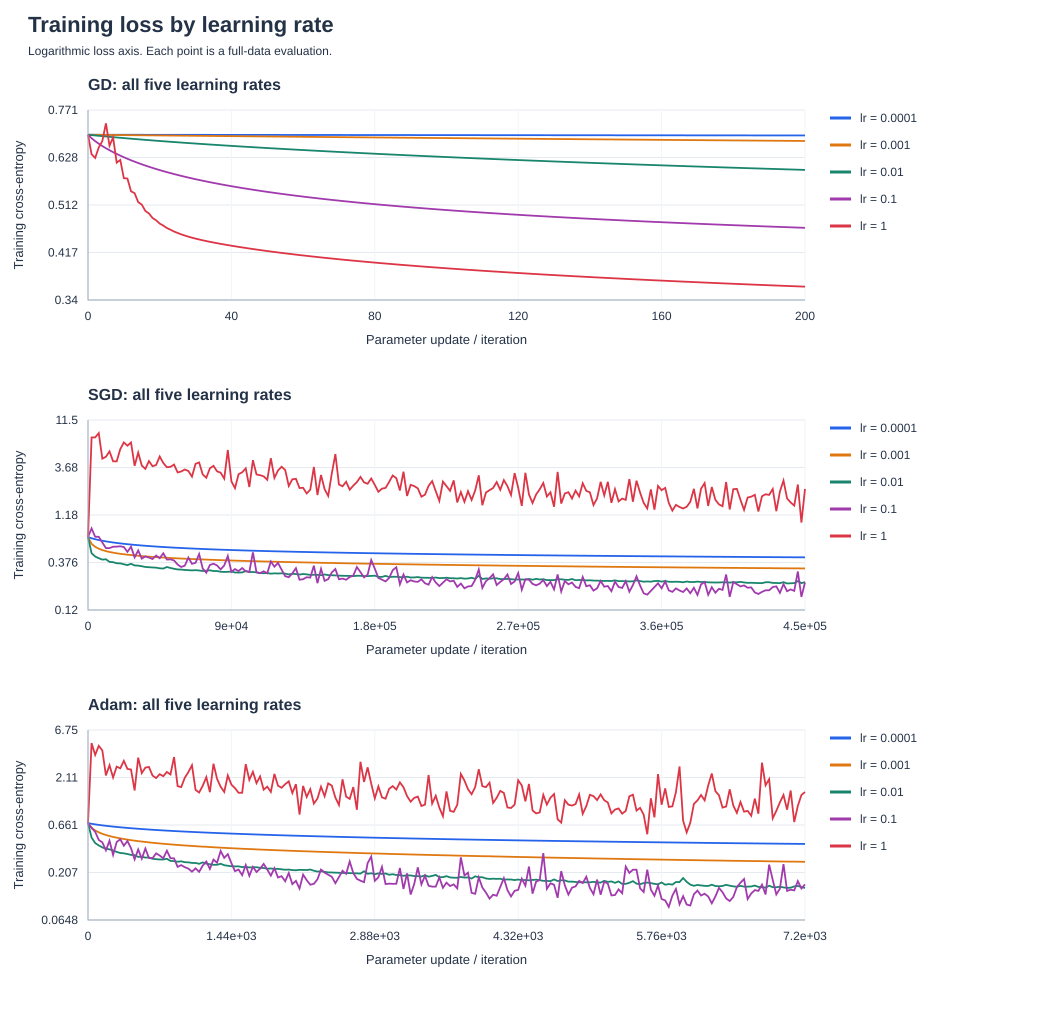

In [6]:
class SVGFigure:
    def __init__(self, svg):
        self.svg = svg

    def _repr_svg_(self):
        return self.svg

    def __repr__(self):
        return "SVG learning-curve figure (also saved as .svg)"


def xml_escape(value):
    return str(value).replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;").replace('"', "&quot;")


def plot_svg(panels, filename, title, xlabel, ylabel, log_y=False, log_x=False):
    """Panels: (title, [(legend, x_values, y_values), ...]); native SVG output."""
    width, panel_height = 1050, 310
    height = 85 + panel_height * len(panels)
    colors = ("#2563eb", "#e07812", "#18856c", "#a13aad", "#dc3545")
    out = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" '
           f'viewBox="0 0 {width} {height}" role="img">',
           f'<title>{xml_escape(title)}</title>', '<rect width="100%" height="100%" fill="#fff"/>',
           '<style>text{font-family:Arial,sans-serif;fill:#243247}.tick{font-size:12px}</style>',
           f'<text x="28" y="32" font-size="22" font-weight="bold">{xml_escape(title)}</text>',
           f'<text x="28" y="55" font-size="12">'
           f'{"Logarithmic loss axis. " if log_y else ""}Each point is a full-data evaluation.</text>']
    for panel_index, (panel_title, series) in enumerate(panels):
        left, right = 88, 805
        top = 110 + panel_index * panel_height
        bottom = top + 190
        xs = np.concatenate([np.asarray(s[1], dtype=float) for s in series])
        ys = np.concatenate([np.asarray(s[2], dtype=float) for s in series])
        assert np.isfinite(xs).all() and np.isfinite(ys).all()
        if log_y:
            assert np.all(ys > 0)
        if log_x:
            assert np.all(xs > 0)
        transform_x = np.log10 if log_x else np.asarray
        transform_y = np.log10 if log_y else np.asarray
        xmin, xmax = float(transform_x(xs).min()), float(transform_x(xs).max())
        ymin, ymax = float(transform_y(ys).min()), float(transform_y(ys).max())
        ypad = max((ymax - ymin) * 0.08, 0.025)
        ymin, ymax = ymin - ypad, ymax + ypad
        if not log_y:
            ymin = max(0, ymin)
        out.append(f'<text x="{left}" y="{top-20}" font-size="16" font-weight="bold">{xml_escape(panel_title)}</text>')
        for tick in np.linspace(ymin, ymax, 5):
            py = bottom - (tick - ymin) / (ymax - ymin) * (bottom - top)
            value = 10**tick if log_y else tick
            out.extend([f'<line x1="{left}" x2="{right}" y1="{py:.2f}" y2="{py:.2f}" stroke="#e5eaf0"/>',
                        f'<text class="tick" x="{left-10}" y="{py+4:.2f}" text-anchor="end">{value:.3g}</text>'])
        x_ticks = np.log10(np.unique(xs)) if log_x else np.linspace(xmin, xmax, 6)
        for tick in x_ticks:
            px = left + (tick - xmin) / max(xmax - xmin, 1e-12) * (right - left)
            value = 10**tick if log_x else tick
            out.extend([f'<line x1="{px:.2f}" x2="{px:.2f}" y1="{top}" y2="{bottom}" stroke="#f1f4f8"/>',
                        f'<text class="tick" x="{px:.2f}" y="{bottom+20}" text-anchor="middle">{value:.3g}</text>'])
        for line_index, (label, x, values) in enumerate(series):
            px = left + (transform_x(np.asarray(x)) - xmin) / max(xmax - xmin, 1e-12) * (right - left)
            py = bottom - (transform_y(np.asarray(values)) - ymin) / (ymax - ymin) * (bottom - top)
            points = " ".join(f"{a:.2f},{b:.2f}" for a, b in zip(px, py))
            color = colors[line_index % len(colors)]
            out.append(f'<polyline fill="none" stroke="{color}" stroke-width="1.8" points="{points}"/>')
            if log_x:
                out.extend(f'<circle cx="{a:.2f}" cy="{b:.2f}" r="3.5" fill="{color}"/>'
                           for a, b in zip(px, py))
            legend_y = top + 8 + line_index * 27
            out.extend([f'<line x1="830" x2="851" y1="{legend_y}" y2="{legend_y}" stroke="{color}" stroke-width="3"/>',
                        f'<text x="860" y="{legend_y+4}" font-size="12">{xml_escape(label)}</text>'])
        out.extend([f'<path d="M {left} {top} V {bottom} H {right}" fill="none" stroke="#9ca9ba"/>',
                    f'<text x="{(left+right)/2}" y="{bottom+44}" font-size="13" text-anchor="middle">{xml_escape(xlabel)}</text>',
                    f'<text transform="translate(23 {(top+bottom)/2}) rotate(-90)" font-size="13" text-anchor="middle">{xml_escape(ylabel)}</text>'])
    out.append('</svg>')
    svg = "\n".join(out)
    with open(filename, "w", encoding="utf-8") as file:
        file.write(svg)
    return SVGFigure(svg)


rate_panels = []
for method in METHODS:
    rate_panels.append((method + ": all five learning rates", [
        (f"lr = {rate:g}", experiments[method, rate]["history"]["updates"],
         experiments[method, rate]["history"]["train_loss"]) for rate in LEARNING_RATES]))
plot_svg(rate_panels, "figures/learning_rates_train.svg", "Training loss by learning rate",
         "Parameter update / iteration", "Training cross-entropy", log_y=True)

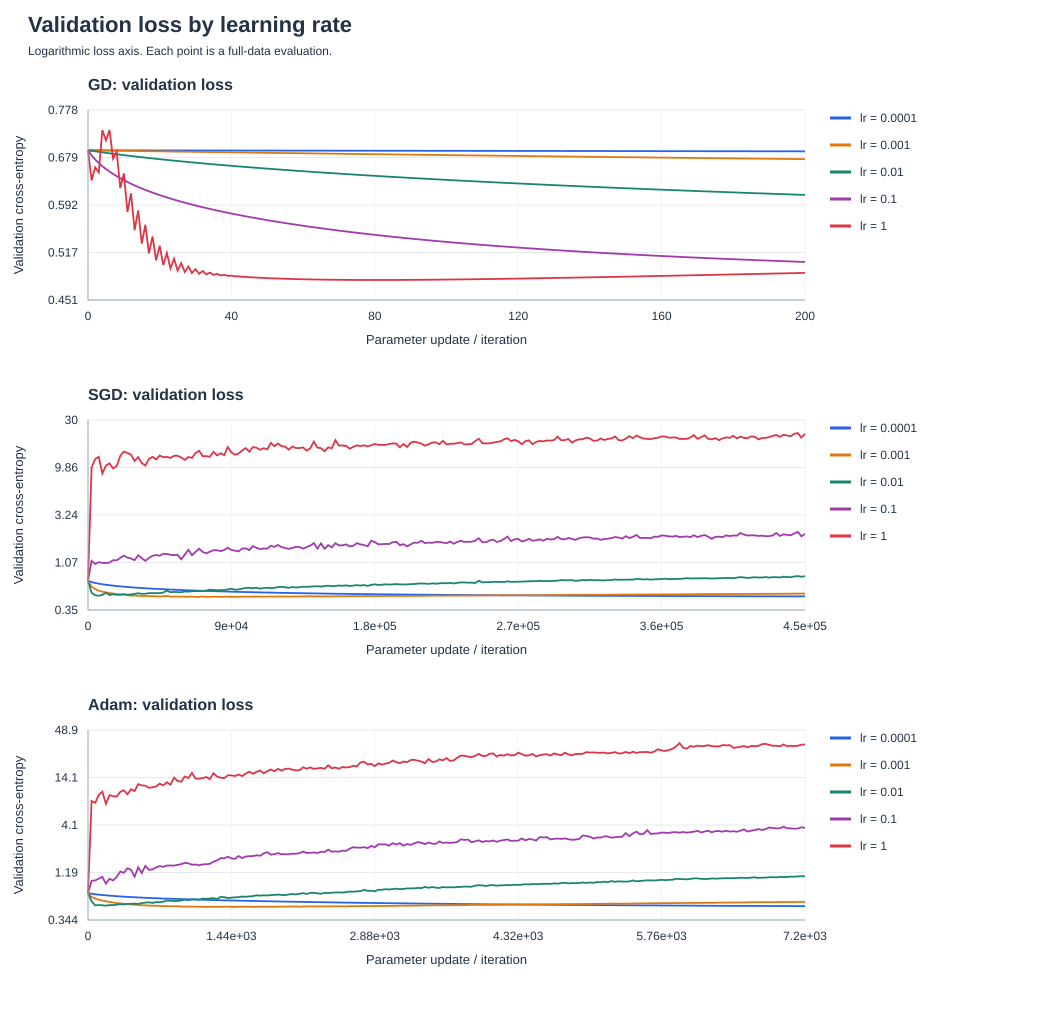

In [7]:
validation_panels = []
for method in METHODS:
    validation_panels.append((method + ": validation loss", [
        (f"lr = {rate:g}", experiments[method, rate]["history"]["updates"],
         experiments[method, rate]["history"]["val_loss"]) for rate in LEARNING_RATES]))
plot_svg(validation_panels, "figures/learning_rates_validation.svg", "Validation loss by learning rate",
         "Parameter update / iteration", "Validation cross-entropy", log_y=True)

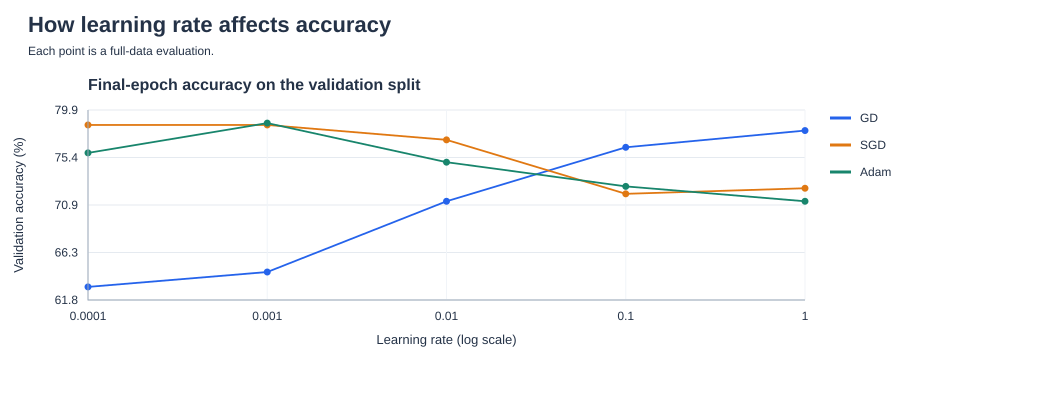

In [8]:
accuracy_series = []
for method in METHODS:
    accuracy_series.append((method, np.array(LEARNING_RATES), np.array([
        100 * experiments[method, rate]["history"]["val_accuracy"][-1] for rate in LEARNING_RATES])))
plot_svg([("Final-epoch accuracy on the validation split", accuracy_series)],
         "figures/learning_rate_accuracy.svg", "How learning rate affects accuracy",
         "Learning rate (log scale)", "Validation accuracy (%)", log_x=True)

## Final training and test results
Each selected model is trained on all 2,813 training molecules for 200 epochs.
The centering means are recalculated from these training rows.

The table reports training and test accuracy, cross-entropy and the number of
parameter updates. Confusion matrices use actual classes as rows and predicted
classes as columns. The baseline always predicts the most frequent training class.

In [9]:
training_mean = X_raw[train_idx].mean(axis=0)
X_train = np.asfortranarray((X_raw[train_idx] - training_mean).T)
X_test = np.asfortranarray((X_raw[test_idx] - training_mean).T)
Y_train, Y_test = y[train_idx][None, :], y[test_idx][None, :]
final_models = {}
for method in METHODS:
    run = model(X_train, Y_train, learning_rate=selected_rates[method], method=method)
    run["test"] = evaluate(run["w"], run["b"], X_test, Y_test)
    run["test_predictions"] = predict(run["w"], run["b"], X_test)
    run["confusion"] = np.bincount(
        2 * Y_test.ravel() + run["test_predictions"].ravel(), minlength=4).reshape(2, 2)
    final_models[method] = run

majority = int(np.argmax(np.bincount(y[train_idx])))
baseline_accuracy = float(np.mean(Y_test == majority))
baseline_loss = binary_loss(np.full_like(Y_test, np.log(Y_train.mean() / (1 - Y_train.mean())),
                                        dtype=float), Y_test)
print(f"Majority-class test accuracy: {100*baseline_accuracy:.2f}% (always class {majority})")
print(f"Constant training-prevalence probability test loss: {baseline_loss:.6f}\n")
print(f"{'Method':<7} {'Rate':>8} {'Updates':>10} {'Train acc':>11} {'Test acc':>11} {'Train loss':>12} {'Test loss':>11}")
for method, run in final_models.items():
    print(f"{method:<7} {run['learning_rate']:8g} {int(run['history']['updates'][-1]):10d} "
          f"{100*run['train']['accuracy']:10.2f}% {100*run['test']['accuracy']:10.2f}% "
          f"{run['train']['loss']:12.6f} {run['test']['loss']:11.6f}")
    assert run["confusion"].sum() == 938
    assert np.isclose(np.trace(run["confusion"]) / 938, run["test"]["accuracy"])
print("\nConfusion matrices: rows = actual [0,1], columns = predicted [0,1]")
for method, run in final_models.items():
    print(method, "\n", run["confusion"])

Majority-class test accuracy: 54.26% (always class 1)
Constant training-prevalence probability test loss: 0.689506

Method      Rate    Updates   Train acc    Test acc   Train loss   Test loss
GD             1        200      83.90%      75.91%     0.371202    0.546764
SGD       0.0001     562600      81.37%      76.01%     0.421950    0.519764
Adam      0.0001       8800      82.23%      75.80%     0.408347    0.506201

Confusion matrices: rows = actual [0,1], columns = predicted [0,1]
GD 
 [[311 118]
 [108 401]]
SGD 
 [[308 121]
 [104 405]]
Adam 
 [[310 119]
 [108 401]]


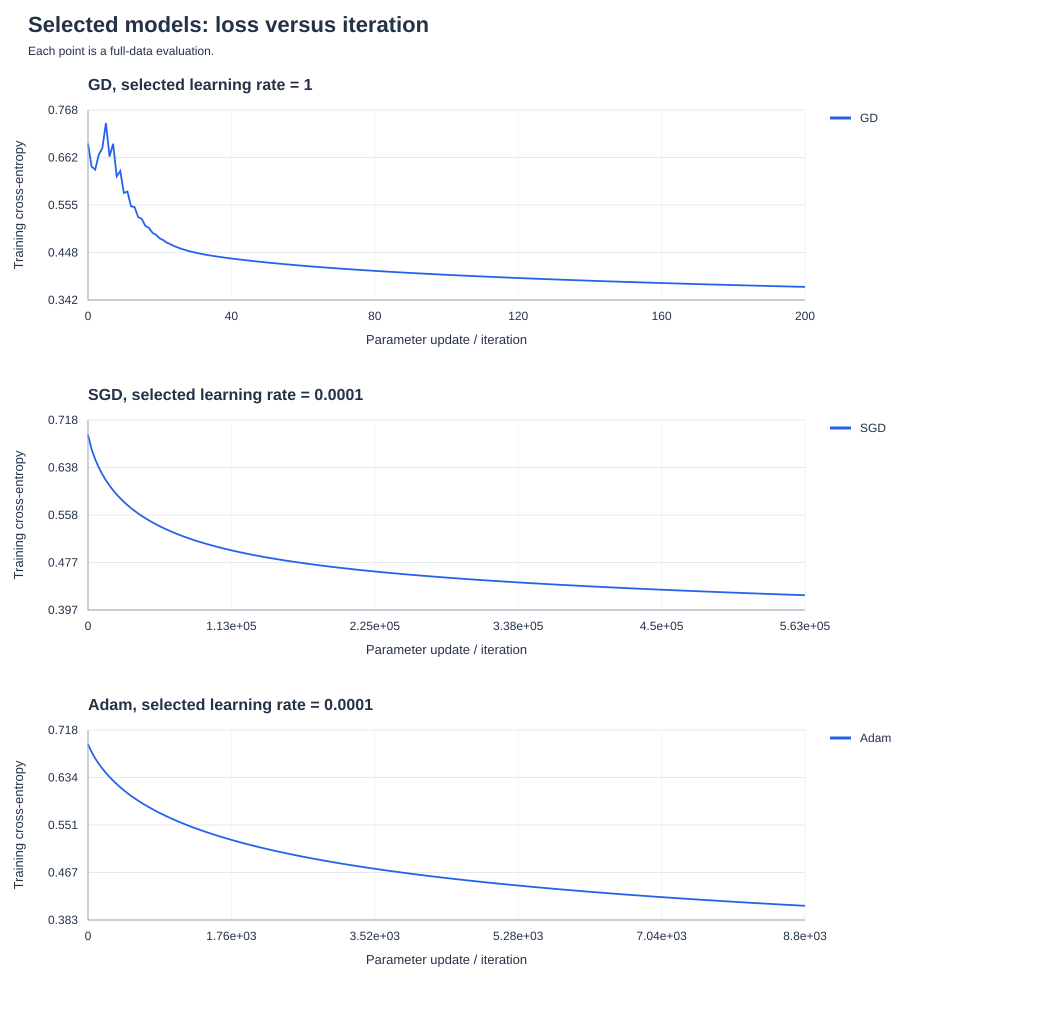

In [10]:
comparison_panels = []
for method, run in final_models.items():
    comparison_panels.append((f"{method}, selected learning rate = {run['learning_rate']:g}",
        [(method, run["history"]["updates"], run["history"]["train_loss"])]))
plot_svg(comparison_panels, "figures/final_loss_iterations.svg", "Selected models: loss versus iteration",
         "Parameter update / iteration", "Training cross-entropy")

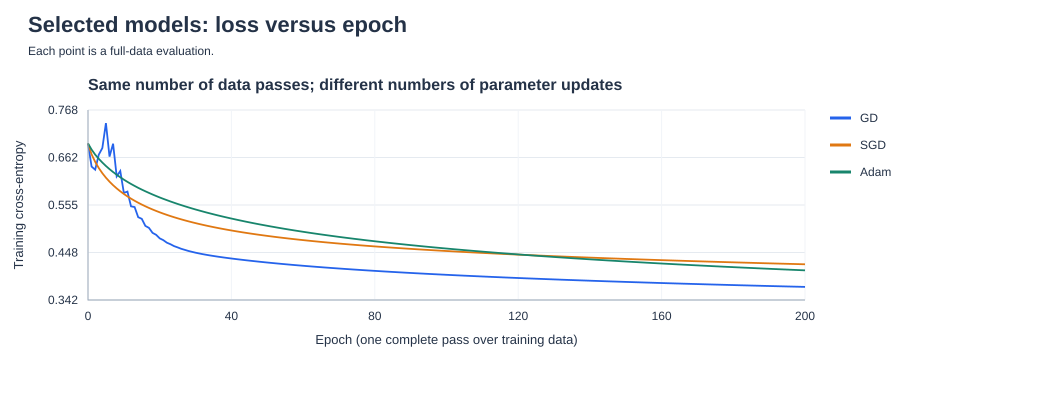

In [11]:
epoch_series = [(method, run["history"]["epoch"], run["history"]["train_loss"])
                for method, run in final_models.items()]
plot_svg([("Same number of data passes; different numbers of parameter updates", epoch_series)],
         "figures/final_loss_epochs.svg", "Selected models: loss versus epoch",
         "Epoch (one complete pass over training data)", "Training cross-entropy")

## 6. Conclusions
The results below compare the selected rates, validation accuracy and final test performance.

In [12]:
print("LEARNING RATE AND ACCURACY")
for method in METHODS:
    best_rate = selected_rates[method]
    chosen = experiments[method, best_rate]["history"]
    low = experiments[method, LEARNING_RATES[0]]["history"]
    high = experiments[method, LEARNING_RATES[-1]]["history"]
    acc_values = [experiments[method, rate]["history"]["val_accuracy"][-1]
                  for rate in LEARNING_RATES]
    accuracy_best_rate = LEARNING_RATES[int(np.argmax(acc_values))]
    print(f"\n{method}: selected lr={best_rate:g} with final validation loss "
          f"{chosen['val_loss'][-1]:.4f} and accuracy {100*chosen['val_accuracy'][-1]:.2f}%.")
    print(f"  Lowest lr={LEARNING_RATES[0]:g}: validation accuracy {100*low['val_accuracy'][-1]:.2f}%; "
          f"highest lr={LEARNING_RATES[-1]:g}: {100*high['val_accuracy'][-1]:.2f}%.")
    print(f"  Highest validation accuracy occurs at lr={accuracy_best_rate:g}; "
          "selection uses cross-entropy, so these criteria can disagree.")

print("\nHELD-OUT PERFORMANCE")
for method, run in final_models.items():
    gap = 100 * (run["train"]["accuracy"] - run["test"]["accuracy"])
    print(f"{method}: test accuracy {100*run['test']['accuracy']:.2f}%, test loss "
          f"{run['test']['loss']:.4f}, train-test accuracy gap {gap:.2f} percentage points.")
winner = max(METHODS, key=lambda method: final_models[method]["test"]["accuracy"])
loss_winner = min(METHODS, key=lambda method: final_models[method]["test"]["loss"])
print(f"\nHighest test accuracy in this experiment: {winner}. Lowest test loss: {loss_winner}.")
correct_counts = [int(np.trace(run["confusion"])) for run in final_models.values()]
print(f"The accuracy spread is only {max(correct_counts)-min(correct_counts)} correctly classified "
      f"molecules out of {Y_test.size}; the ranking is weak evidence of an optimizer advantage.")
print("This is a description of this fixed split, not proof that one optimizer is universally best.")

LEARNING RATE AND ACCURACY

GD: selected lr=1 with final validation loss 0.4873 and accuracy 77.98%.
  Lowest lr=0.0001: validation accuracy 63.06%; highest lr=1: 77.98%.
  Highest validation accuracy occurs at lr=1; selection uses cross-entropy, so these criteria can disagree.

SGD: selected lr=0.0001 with final validation loss 0.4818 and accuracy 78.51%.
  Lowest lr=0.0001: validation accuracy 78.51%; highest lr=1: 72.47%.
  Highest validation accuracy occurs at lr=0.0001; selection uses cross-entropy, so these criteria can disagree.

Adam: selected lr=0.0001 with final validation loss 0.4939 and accuracy 75.84%.
  Lowest lr=0.0001: validation accuracy 75.84%; highest lr=1: 71.23%.
  Highest validation accuracy occurs at lr=0.001; selection uses cross-entropy, so these criteria can disagree.

HELD-OUT PERFORMANCE
GD: test accuracy 75.91%, test loss 0.5468, train-test accuracy gap 7.99 percentage points.
SGD: test accuracy 76.01%, test loss 0.5198, train-test accuracy gap 5.36 percent

GD reaches 75.91% test accuracy, SGD 76.01% and Adam 75.80%, compared with
54.26% for the majority-class baseline. SGD has the highest accuracy, but its
advantage is only one correct prediction over GD and two over Adam. Adam has
the lowest test cross-entropy (0.5062).

The effect of the learning rate differs between optimizers. GD learns slowly at
0.0001 and 0.001; its best validation loss in this grid is at 1.0. SGD and Adam
select 0.0001. Their larger rates often reduce training loss while increasing
validation loss, which shows that better fitting does not always improve generalization.

For Adam, the highest validation accuracy is at 0.001, while the lowest validation
loss is at 0.0001. Accuracy checks the final class decision; cross-entropy also
penalizes confident incorrect predictions. This explains why the two criteria
can prefer different learning rates.

The loss curves show smooth progress for small learning rates and larger
fluctuations for aggressive SGD and Adam updates. Some within-epoch fluctuations
are not visible because the full-data loss is recorded only at epoch boundaries.
Logistic regression has a convex loss, so these differences concern the update
rule, conditioning and training budget rather than different local minima.

These results use one row-level split and one seed. The accuracy differences are
too small to support a general claim that one optimizer is better. The comparison
also depends on the batch sizes, centering and the 200-epoch budget. Without
molecular group identifiers, it does not test generalization to separate chemical families.

### References
- MLT 2026, Homework assignment 3.
- Course notebook: `Logistic_Regression_as_a_Neural_Network_BP_alg (5).ipynb`.
- Lecture 6-1: *Optimization Algorithms*.
- Lecture 6-2: *MLP and backpropagation*.
- Dataset: `bioresponse.csv`, provided with the assignment.

## Export results
The CSV files store the experiment tables and learning curves. The NPZ file stores
the split indices, feature means, model parameters and test predictions.
For predictions on new rows, subtract `training_mean` before computing $\sigma(w^T X+b)$.

In [13]:
rate_rows = []
for method in METHODS:
    for rate in LEARNING_RATES:
        run = experiments[method, rate]
        h = run["history"]
        rate_rows.append([method, rate, int(h["updates"][-1]), h["train_loss"][-1],
                          h["val_loss"][-1], h["train_accuracy"][-1], h["val_accuracy"][-1]])
        np.savetxt(f"results/{method}_lr_{rate:g}_history.csv",
                   np.column_stack([h[key] for key in h]), delimiter=",",
                   header=",".join(h), comments="")
np.savetxt("results/learning_rate_results.csv", np.asarray(rate_rows, dtype=str), fmt="%s",
           delimiter=",", header="method,learning_rate,updates,train_loss,val_loss,train_accuracy,val_accuracy", comments="")

final_rows = [[method, run["learning_rate"], int(run["history"]["updates"][-1]),
               run["train"]["accuracy"], run["test"]["accuracy"],
               run["train"]["loss"], run["test"]["loss"]] for method, run in final_models.items()]
np.savetxt("results/final_model_results.csv", np.asarray(final_rows, dtype=str), fmt="%s", delimiter=",",
           header="method,learning_rate,updates,train_accuracy,test_accuracy,train_loss,test_loss", comments="")
for method, run in final_models.items():
    h = run["history"]
    keys = ("epoch", "updates", "train_loss", "train_accuracy")
    np.savetxt(f"results/{method}_final_history.csv", np.column_stack([h[key] for key in keys]),
               delimiter=",", header=",".join(keys), comments="")
archive = {"train_indices": train_idx, "test_indices": test_idx,
           "inner_fit_indices": fit_idx, "validation_indices": val_idx,
           "training_mean": training_mean, "test_labels": Y_test,
           "feature_names": np.array(columns[1:]), "seed": SEED, "epochs": EPOCHS}
for method, run in final_models.items():
    archive.update({f"{method}_w": run["w"], f"{method}_b": run["b"],
                    f"{method}_learning_rate": run["learning_rate"],
                    f"{method}_test_predictions": run["test_predictions"]})
np.savez_compressed("results/fitted_models.npz", **archive)
print("Saved five SVG figures, all result tables, curve histories and fitted model parameters.")

Saved five SVG figures, all result tables, curve histories and fitted model parameters.
